# Deep stochastic control (Han & E, 2016) learns Bartlett's delta in lognormal SABR

**Claim to test.** In the lognormal SABR model the variance-optimal (quadratic) hedge of a call coincides with
Bartlett's delta (Keller-Ressel 2022, *Bartlett's Delta revisited*, Thm 3.1). Quadratic hedging is a stochastic
control problem, so the Han–E deep-learning approximation for stochastic control — one feed-forward subnetwork per
time step, stacked through the dynamics, trained by Monte-Carlo SGD on the control objective — should *discover*
Bartlett's delta from simulated paths alone, without ever being shown the formula, and should **not** land on the
Black–Scholes (implied) delta.

**What the notebook does**

1. Implements the model, the implied-vol approximation $\hat\Sigma$, and the three hedge ratios compared in the paper:
   the Black–Scholes delta $\Phi(\hat d_+)$, the HKLW adjustment, and Bartlett's delta (closed form, cross-checked by autograd).
2. Formulates quadratic hedging as a Han–E control problem and trains the stacked policy network (GPU if available).
3. Compares the learned hedge ratio with the three analytic ones — state by state along the paths, and through realised
   hedging errors — and compares the learned initial capital with the option price.

References — Han & E, *Deep Learning Approximation for Stochastic Control Problems*, arXiv:1611.07422 (2016) ·
Keller-Ressel, *Bartlett's Delta revisited: variance-optimal hedging in the lognormal SABR and in the rough Bergomi model*,
arXiv:2207.13573 (2022) · Bartlett, *Hedging under SABR model*, Wilmott (2006) · Hagan–Kumar–Lesniewski–Woodward,
*Managing smile risk*, Wilmott (2002) · Hagan & Lesniewski, *Bartlett's delta in the SABR model*, arXiv:1704.03110 (2017).

## 1. Model, implied volatility, and the three hedge ratios

Lognormal SABR ($\beta=1$), zero rates, pricing measure:

$$dS_t = S_t\,\alpha_t\,dB_t,\qquad d\alpha_t = \tfrac{\eta}{2}\,\alpha_t\,dW_t,\qquad d\langle B,W\rangle_t=\rho\,dt .$$

Implied-vol approximation (Keller-Ressel eqs. (14)–(15); this is Hagan's $z/x(z)$ with $y=-2z$, without the $O(T)$ term):

$$\hat\Sigma_t=\alpha_t\, f(Y_t),\qquad Y_t=\frac{\eta}{\alpha_t}\log\frac{K}{S_t},\qquad
f(y)=\frac{y}{g(y)},\qquad g(y)=-2\log\frac{\sqrt{1+\rho y+y^2/4}-\rho-y/2}{1-\rho}.$$

The call is priced as $C_t=c_{BS}(T-t,S_t,\hat\Sigma_t)$. With $F_1=f-yf'=\partial\hat\Sigma/\partial\alpha$ and
$F_2=-2f'=\tfrac{2S}{\eta}\,\partial\hat\Sigma/\partial S$ (Remark 3.1), the three strategies of §3.1 are

| strategy | hedge ratio $\theta_t$ | what is allowed to move with $S$ |
|---|---|---|
| **Black–Scholes (implied) delta** | $\Phi(\hat d_+)$ | nothing: the implied vol is frozen |
| HKLW delta (Hagan et al. 2002, eq. (3)) | $\Phi(\hat d_+)+\tfrac{\eta}{2}\phi(\hat d_+)\sqrt{T-t}\;F_2(Y_t)$ | the smile slides with $S$, $\alpha$ frozen |
| **Bartlett's delta** (2006; eq. (16)) | $\Phi(\hat d_+)+\tfrac{\eta}{2}\phi(\hat d_+)\sqrt{T-t}\;\big(\rho F_1(Y_t)+F_2(Y_t)\big)$ | the smile slides **and** $\alpha$ moves by its regression on $dS$: $\;E[d\alpha\mid dS]=\rho\,\tfrac{\eta}{2S}\,dS$ |

The last column is the whole distinction. Bartlett's delta is the Black–Scholes delta plus vega times
$d\langle\hat\Sigma,S\rangle_t/d\langle S,S\rangle_t$, i.e. the variance-optimal (Föllmer–Schweizer) projection
$\theta^{VO}_t=d\langle C,S\rangle_t/d\langle S,S\rangle_t$ (Thm 2.1 → Thm 3.1). For $\rho=0$ Bartlett = HKLW;
neither equals the Black–Scholes delta unless the smile is flat.

In [1]:
import math, time
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ON_GPU = device.type == 'cuda'
if ON_GPU: torch.cuda.manual_seed_all(0)
print(f'device: {device}' + (f'  ({torch.cuda.get_device_name(0)})' if ON_GPU else '   <- no GPU found: reduced batch / iterations'))

# model & contract: the lognormal-SABR test case of Keller-Ressel (2022), Sec. 5  (vol-of-vol is eta/2 = 0.25 in Hagan's notation)
S0, ALPHA0, ETA, RHO, T, K = 1.0, 0.4, 0.5, -0.9, 1.0, 1.0
N_STEPS = 100                     # rebalancing grid; the discrete optimum -> Bartlett as N_STEPS -> inf
dt = T / N_STEPS

# Han-E training budget
BATCH   = 8192  if ON_GPU else 2048
N_ITERS = 5000  if ON_GPU else 2500
N_TEST  = 2**17 if ON_GPU else 2**15
WIDTH, USE_BN, LR = 32, False, 2e-3          # USE_BN=True reproduces Han & E's batch-normalised subnetworks (see the note in Sec. 2)

COL   = dict(learned='#2a78d6', bartlett='#eb6834', hklw='#1baf7a', bs='#333333')
LABEL = dict(learned='learned (Han–E)', bartlett="Bartlett's delta", hklw='HKLW delta', bs='Black–Scholes delta')

device: cpu   <- no GPU found: reduced batch / iterations


In [2]:
SQRT2, SQRT2PI = math.sqrt(2.0), math.sqrt(2*math.pi)
Phi = lambda x: 0.5*(1.0 + torch.erf(x/SQRT2))
phi = lambda x: torch.exp(-0.5*x*x)/SQRT2PI

def f_sabr(y, rho=RHO):
    '''f(y) = y/g(y),  g(y) = -2 log((sqrt(1+rho y+y^2/4) - rho - y/2)/(1-rho))        [KR22 eq. (15)]'''
    small = y.abs() < 1e-3
    ys = torch.where(small, torch.ones_like(y), y)                 # keeps the exact branch NaN-free under autograd
    g  = -2.0*torch.log((torch.sqrt(1 + rho*ys + ys*ys/4) - rho - ys/2)/(1 - rho))
    series = 1 + rho*y/4 + (2 - 3*rho**2)*y*y/48                   # Taylor expansion at y = 0
    return torch.where(small, series, ys/g)

def F1_F2(y, rho=RHO):
    '''F1 = f - y f' = f^2/sqrt(1+rho y+y^2/4),   F2 = -2 f' = (2/y)(F1 - f)             [KR22 Remark 3.1(b)]'''
    f  = f_sabr(y, rho)
    F1 = f*f/torch.sqrt(1 + rho*y + y*y/4)
    small = y.abs() < 1e-3
    ys = torch.where(small, torch.ones_like(y), y)
    F2 = torch.where(small, -rho/2 - (2 - 3*rho**2)*y/12, 2*(F1 - f)/ys)
    return F1, F2

def sigma_hat(S, alpha):
    '''Sigma-hat = alpha f(Y),  Y = (eta/alpha) log(K/S)                                   [KR22 eq. (14)]'''
    Y = (ETA/alpha)*torch.log(K/S)
    return alpha*f_sabr(Y), Y

def black_scholes(S, sigma, tau):
    '''returns price, Delta = Phi(d+), Vega = S phi(d+) sqrt(tau), d+   (zero rates, undiscounted)'''
    v  = sigma*torch.sqrt(tau)
    dp = torch.log(S/K)/v + v/2
    return S*Phi(dp) - K*Phi(dp - v), Phi(dp), S*phi(dp)*torch.sqrt(tau), dp

def hedge_ratios(S, alpha, tau):
    '''The three strategies of KR22 Sec. 3.1 in closed form (shapes broadcast; use float64).'''
    sig, Y = sigma_hat(S, alpha)
    price, delta, vega, dp = black_scholes(S, sig, tau)
    F1, F2 = F1_F2(Y)
    c = (ETA/2)*phi(dp)*torch.sqrt(tau)                            # = (eta/(2S)) * Vega
    return dict(price=price, bs=delta, hklw=delta + c*F2, bartlett=delta + c*(RHO*F1 + F2))

def hedge_ratios_autograd(S, alpha, tau):
    '''Same objects from dC/dS and dC/dalpha by autograd:  theta_VO = C_S + C_alpha * d<alpha,S>/d<S,S>,
       d<alpha,S>/d<S,S> = (eta/2) alpha * S alpha rho / (S^2 alpha^2) = rho eta / (2 S).'''
    S = S.clone().requires_grad_(True); alpha = alpha.clone().requires_grad_(True)
    price = black_scholes(S, sigma_hat(S, alpha)[0], tau)[0]
    C_S, C_a = torch.autograd.grad(price.sum(), (S, alpha))
    return dict(hklw=C_S, bartlett=C_S + C_a*RHO*ETA/(2*S.detach()))

# closed form vs autograd on a grid of states (S, alpha, time-to-maturity)
grid = torch.meshgrid(torch.linspace(0.5, 1.8, 40, dtype=torch.float64), torch.linspace(0.15, 0.9, 30, dtype=torch.float64),
                      torch.tensor([0.02, 0.25, 0.5, 1.0], dtype=torch.float64), indexing='ij')
Sg, Ag, Tg = (x.reshape(-1).to(device) for x in grid)
cf, ag = hedge_ratios(Sg, Ag, Tg), hedge_ratios_autograd(Sg, Ag, Tg)
print('max |closed form - autograd| :  HKLW %.1e    Bartlett %.1e' %
      ((cf['hklw'] - ag['hklw']).abs().max(), (cf['bartlett'] - ag['bartlett']).abs().max()))

atm = hedge_ratios(*(torch.tensor([v], dtype=torch.float64, device=device) for v in (S0, ALPHA0, T)))
print(f"t = 0, ATM:   Black-Scholes delta {atm['bs'].item():.4f}    HKLW {atm['hklw'].item():.4f}    "
      f"Bartlett {atm['bartlett'].item():.4f}      (Sigma-hat price {atm['price'].item():.4f})")

max |closed form - autograd| :  HKLW 3.4e-15    Bartlett 3.4e-15
t = 0, ATM:   Black-Scholes delta 0.5793    HKLW 0.6233    Bartlett 0.5353      (Sigma-hat price 0.1585)


## 2. Quadratic hedging as a Han–E stochastic control problem

Discretise $[0,T]$ into $N$ steps. Han & E (2016) write a control problem as $s_{k+1}=s_k+b_k(s_k,a_k)+\xi_{k+1}$
with cost $\sum_k c_k(s_k,a_k)$, approximate every control by a feed-forward subnetwork $a_k=\pi_k(s_k;\theta_k)$, and stack
the subnetworks *through the model dynamics* into one deep network whose loss is the Monte-Carlo estimate of the cost.
Here:

* **state** $s_k=(S_k,\alpha_k,V_k)$, $V_k$ the value of the hedging portfolio;
* **noise** $\xi_{k+1}=(\Delta B_k,\Delta W_k)$, correlated Gaussians;
* **control** $a_k=\pi_k(S_k,\alpha_k)$ = units of $S$ held on $[t_k,t_{k+1})$ (the control feeds into $V$ only, not into $(S,\alpha)$);
* **dynamics**: exact lognormal step for $\alpha$, log-Euler step for $S$, $V_{k+1}=V_k+a_k\,(S_{k+1}-S_k)$;
* **cost**: terminal only, $\big((S_N-K)^+-w-V_N\big)^2$ — the mean-square hedging error (MSHE) of KR22 eq. (5) —
  with the initial capital $w$ a trainable scalar (its optimum is $E[(S_N-K)^+]$ because $S$ is a martingale).

```
 (S0,a0) ──► π_0 ──► a_0 ─┐                 (S1,a1) ──► π_1 ──► a_1 ─┐                       (S_{N-1},a_{N-1}) ──► π_{N-1} ─┐
    │                     ▼                     │                     ▼                              │                       ▼
    └──── ξ_1 ──► SABR step ──► V_1 = a_0 ΔS_0 ─┴──── ξ_2 ──► SABR step ──► V_2 ── ··· ──────────────┴── ξ_N ──► V_N ──► loss = ((S_N-K)^+ - w - V_N)^2
```

Architecture as in Han & E §3: each subnetwork is input → 2 hidden layers → output; at $k=0$ the state is deterministic so
$\pi_0$ is a single trainable number (as in the paper); Adam on fresh Monte-Carlo noise every iteration (antithetic pairs).
The subnetwork inputs are the state in natural coordinates — log-moneyness in units of $\alpha_k\sqrt{T-t_k}$ and
$\log\alpha_k$ — a fixed rescaling that carries no information about $\hat\Sigma$, $F_1$, $F_2$ or $\rho$.
Because $S$ is a martingale, the global quadratic criterion and the local (Föllmer–Schweizer) one have the same minimiser,
so the learned $a_k$ should approach $\theta^{VO}(t_k,S_k,\alpha_k)$ — Bartlett's delta — as $N\to\infty$.
Nothing in the training loop knows about $\hat\Sigma$, $F_1$, $F_2$ or any Greek.

*Note on batch normalisation.* Han & E put BN after every linear map. It is available here (`USE_BN=True`) but off by
default: BN re-standardises each subnetwork's pre-activations with batch statistics, and near maturity that compresses the
$\pm1$ moneyness band in which the hedge switches from 0 to 1, so the last subnetworks fit a blurred step. In a short
ablation (600 iterations) the RMS error against Bartlett's delta for $t>0.9$ was 0.06–0.09 with BN and 0.015 without, with
identical errors for $t<0.6$; BN also made each iteration ~50% slower. The methodology — one subnetwork per step, stacked
through the dynamics, Monte-Carlo SGD on the control cost — is unchanged.

In [3]:
def simulate(n, antithetic=True):
    '''Lognormal-SABR paths on the hedging grid (float64): exact step for alpha, log-Euler step for S with alpha frozen on each step.'''
    m = n//2 if antithetic else n
    Z = torch.randn(m, N_STEPS, 2, device=device, dtype=torch.float64)
    if antithetic: Z = torch.cat([Z, -Z], 0)
    dB = math.sqrt(dt)*Z[..., 0]
    dW = math.sqrt(dt)*(RHO*Z[..., 0] + math.sqrt(1 - RHO**2)*Z[..., 1])
    S = torch.empty(Z.shape[0], N_STEPS + 1, device=device, dtype=torch.float64); A = torch.empty_like(S)
    S[:, 0], A[:, 0] = S0, ALPHA0
    for k in range(N_STEPS):
        a = A[:, k]
        S[:, k+1] = S[:, k]*torch.exp(a*dB[:, k] - 0.5*a*a*dt)
        A[:, k+1] = a*torch.exp(0.5*ETA*dW[:, k] - ETA**2*dt/8)
    return S, A

TAU = T - dt*torch.arange(N_STEPS, device=device, dtype=torch.float64)      # time to maturity at each decision time t_k

def terminal_errors_analytic(S, A, w):
    '''L_T = (S_T-K)^+ - w - sum_k theta_k (S_{k+1}-S_k) for the three analytic strategies on the same grid and paths.'''
    th = hedge_ratios(S[:, :-1], A[:, :-1], TAU)
    dS = S[:, 1:] - S[:, :-1]
    payoff = (S[:, -1] - K).clamp(min=0)
    return {s: payoff - w - (th[s]*dS).sum(1) for s in ('bs', 'hklw', 'bartlett')}

In [4]:
class SubNet(nn.Module):
    '''Han-E subnetwork:  state -> [Linear -> BatchNorm -> activation] x 2 -> Linear -> control.'''
    def __init__(self, d_in=2, width=WIDTH, bn=USE_BN):
        super().__init__()
        layers = []
        for i, o in ((d_in, width), (width, width)):
            layers += [nn.Linear(i, o)] + ([nn.BatchNorm1d(o)] if bn else []) + [nn.SiLU()]
        self.net = nn.Sequential(*layers, nn.Linear(width, 1))
        nn.init.constant_(self.net[-1].bias, 0.5)                  # start every hedge ratio near 1/2: no model information
    def forward(self, x): return self.net(x).squeeze(-1)

class HanEPolicy(nn.Module):
    '''Stacked controls a_k = pi_k(S_k, alpha_k), k = 0..N-1, plus the initial capital w.'''
    def __init__(self, n_steps, w0):
        super().__init__()
        self.a0   = nn.Parameter(torch.tensor(0.5))                # k = 0: deterministic state -> the control is a number
        self.nets = nn.ModuleList([SubNet() for _ in range(n_steps - 1)])
        self.w    = nn.Parameter(torch.tensor(float(w0)))
    @staticmethod
    def features(k, S, A):
        '''The state (S_k, alpha_k) in natural coordinates: log-moneyness in units of alpha_k*sqrt(T - t_k) (clipped where the
           hedge is saturated at 0 or 1) and standardised log-vol. A fixed rescaling of the state: nothing about Sigma-hat,
           F1, F2 or the correlation enters here.'''
        x1 = (torch.log(S/K)/(A*math.sqrt(T - k*dt))).clamp(-6, 6)
        x2 = torch.log(A/ALPHA0)/(0.5*ETA*math.sqrt(T))
        return torch.stack([x1, x2], -1)
    def hedge(self, k, S, A):
        return self.a0.expand(S.shape[0]) if k == 0 else self.nets[k-1](self.features(k, S, A))
    def forward(self, S, A):
        '''Unroll the dynamics  V_{k+1} = V_k + a_k (S_{k+1}-S_k)  and return the terminal hedging error L_T.'''
        V = torch.zeros(S.shape[0], device=S.device, dtype=S.dtype)
        for k in range(N_STEPS):
            V = V + self.hedge(k, S[:, k], A[:, k])*(S[:, k+1] - S[:, k])
        return (S[:, -1] - K).clamp(min=0) - self.w - V

policy = HanEPolicy(N_STEPS, w0=atm['price'].item()).to(device)    # premium initialised at the model price, controls at 1/2
print(f'{sum(p.numel() for p in policy.parameters()):,} trainable parameters in {N_STEPS} stacked subnetworks')

117,317 trainable parameters in 100 stacked subnetworks


In [5]:
opt   = torch.optim.Adam(policy.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=N_ITERS, eta_min=LR/40)
hist  = torch.zeros(N_ITERS, device=device)
t0 = time.time(); policy.train()
for it in range(N_ITERS):
    S, A = simulate(BATCH)                                          # fresh Monte-Carlo noise every iteration
    loss = (policy(S.float(), A.float())**2).mean()                 # MSHE = the Han-E cost functional
    opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
    hist[it] = loss.detach()
    if it % (N_ITERS//10) == 0 or it == N_ITERS - 1:
        print(f'iter {it:5d}   MSHE {loss.item():.3e}   w {policy.w.item():.4f}   a_0 {policy.a0.item():.4f}   {time.time()-t0:6.1f}s')
hist = hist.cpu().numpy()

iter     0   MSHE 1.585e-02   w 0.1605   a_0 0.5020      0.2s


iter   250   MSHE 3.202e-04   w 0.1546   a_0 0.5343     31.3s


iter   500   MSHE 2.968e-04   w 0.1551   a_0 0.5382     62.9s


iter   750   MSHE 3.016e-04   w 0.1542   a_0 0.5350     93.8s


iter  1000   MSHE 3.000e-04   w 0.1546   a_0 0.5366    124.5s


...

iter  1500   MSHE 2.835e-04   w 0.1553   a_0 0.5356    186.8s


iter  1750   MSHE 2.856e-04   w 0.1548   a_0 0.5380    217.1s


iter  2000   MSHE 2.899e-04   w 0.1548   a_0 0.5363    248.3s


iter  2250   MSHE 2.821e-04   w 0.1549   a_0 0.5373    279.3s


iter  2499   MSHE 2.633e-04   w 0.1549   a_0 0.5372    310.0s


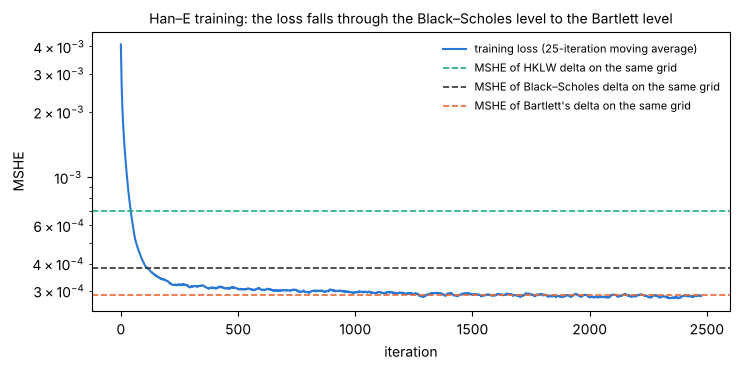

In [6]:
# reference levels: MSHE of the three analytic strategies on the same grid, measured on a fresh batch
with torch.no_grad():
    Sv, Av = simulate(N_TEST)
    ref_mshe = {s: (e**2).mean().item() for s, e in terminal_errors_analytic(Sv, Av, w=(Sv[:, -1] - K).clamp(min=0).mean()).items()}
    del Sv, Av

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(np.convolve(hist, np.ones(25)/25, mode='valid'), color=COL['learned'], lw=1.5, label='training loss (25-iteration moving average)')
for s in ('hklw', 'bs', 'bartlett'):
    ax.axhline(ref_mshe[s], color=COL[s], ls='--', lw=1.2, label=f'MSHE of {LABEL[s]} on the same grid')
ax.set_yscale('log'); ax.set_xlabel('iteration'); ax.set_ylabel('MSHE'); ax.legend(frameon=False, fontsize=8)
ax.set_title('Han–E training: the loss falls through the Black–Scholes level to the Bartlett level', fontsize=10)
plt.tight_layout(); plt.show()

## 3. Learned control vs. Bartlett, HKLW and Black–Scholes

Everything below is out-of-sample: fresh test paths, policy in eval mode. All four strategies use the **same** initial
capital $w=E[(S_T-K)^+]$ (Monte-Carlo), so their hedging errors differ only through the hedge ratios.

In [7]:
policy.eval()
with torch.no_grad():
    S, A = simulate(N_TEST)
    payoff = (S[:, -1] - K).clamp(min=0); w_mc = payoff.mean().item()
    theta = hedge_ratios(S[:, :-1], A[:, :-1], TAU)                                    # analytic hedge ratios along the paths
    theta['learned'] = torch.stack([policy.hedge(k, S[:, k].float(), A[:, k].float()) for k in range(N_STEPS)], 1).double()
    dS = S[:, 1:] - S[:, :-1]
    L  = {s: payoff - w_mc - (theta[s]*dS).sum(1) for s in ('bs', 'hklw', 'bartlett', 'learned')}

    # KR22 Thm 3.2: continuous-time MSHE 'within approximation', evaluated as a path integral on the same paths
    sig, Y = sigma_hat(S[:, :-1], A[:, :-1]); vega = black_scholes(S[:, :-1], sig, TAU)[2]; F1, F2 = F1_F2(Y)
    base = ETA**2/4*(vega**2*A[:, :-1]**2*dt)
    mshe_paper = dict(bs=(base*(F1**2 + 2*RHO*F1*F2 + F2**2)).sum(1).mean().item(),
                      hklw=(base*F1**2).sum(1).mean().item(), bartlett=(base*(1 - RHO**2)*F1**2).sum(1).mean().item())

rmse = {s: (L[s]**2).mean().sqrt().item() for s in L}
print(f"{'strategy':22s}{'RMSE (simulated)':>18s}{'MSHE (simulated)':>18s}{'MSHE (KR22 Thm 3.2)':>22s}{'RMSE reduction vs BS':>24s}")
for s in ('bs', 'hklw', 'bartlett', 'learned'):
    paper = f"{mshe_paper[s]:22.2e}" if s in mshe_paper else f"{'—':>22s}"
    print(f"{LABEL[s]:22s}{rmse[s]:18.4f}{rmse[s]**2:18.2e}{paper}{1 - rmse[s]/rmse['bs']:24.1%}")
print(f"\nfirst-order prediction of the Bartlett-vs-BS RMSE reduction, KR22 eq. (27): {1 - 2*math.sqrt((1 - RHO**2)/(4 - 3*RHO**2)):.1%}")
print(f"(the simulated MSHEs also contain the discrete-rebalancing error of the N = {N_STEPS} grid, common to all four strategies)")

sig_hagan_atm = ALPHA0*(1 + (RHO*ETA*ALPHA0/8 + (2 - 3*RHO**2)*ETA**2/96)*T)         # Hagan's O(T) term, beta = 1
hagan_price = black_scholes(*(torch.tensor([v], dtype=torch.float64) for v in (S0, sig_hagan_atm, T)))[0].item()
print(f"\ninitial capital:  learned w = {policy.w.item():.4f}    MC price = {w_mc:.4f}    "
      f"Sigma-hat price = {atm['price'].item():.4f}    Hagan price incl. O(T) term = {hagan_price:.4f}")
print(f"t = 0 control:    learned a_0 = {policy.a0.item():.4f}    Bartlett = {atm['bartlett'].item():.4f}    "
      f"HKLW = {atm['hklw'].item():.4f}    Black-Scholes = {atm['bs'].item():.4f}")

strategy                RMSE (simulated)  MSHE (simulated)   MSHE (KR22 Thm 3.2)    RMSE reduction vs BS
Black–Scholes delta               0.0194          3.77e-04              2.13e-04                    0.0%
HKLW delta                        0.0263          6.91e-04              5.42e-04                  -35.3%
Bartlett's delta                  0.0168          2.82e-04              1.03e-04                   13.6%
learned (Han–E)                   0.0169          2.84e-04                     —                   13.2%

first-order prediction of the Bartlett-vs-BS RMSE reduction, KR22 eq. (27): 30.4%
(the simulated MSHEs also contain the discrete-rebalancing error of the N = 100 grid, common to all four strategies)

initial capital:  learned w = 0.1549    MC price = 0.1538    Sigma-hat price = 0.1585    Hagan price incl. O(T) term = 0.1548
t = 0 control:    learned a_0 = 0.5372    Bartlett = 0.5353    HKLW = 0.6233    Black-Scholes = 0.5793


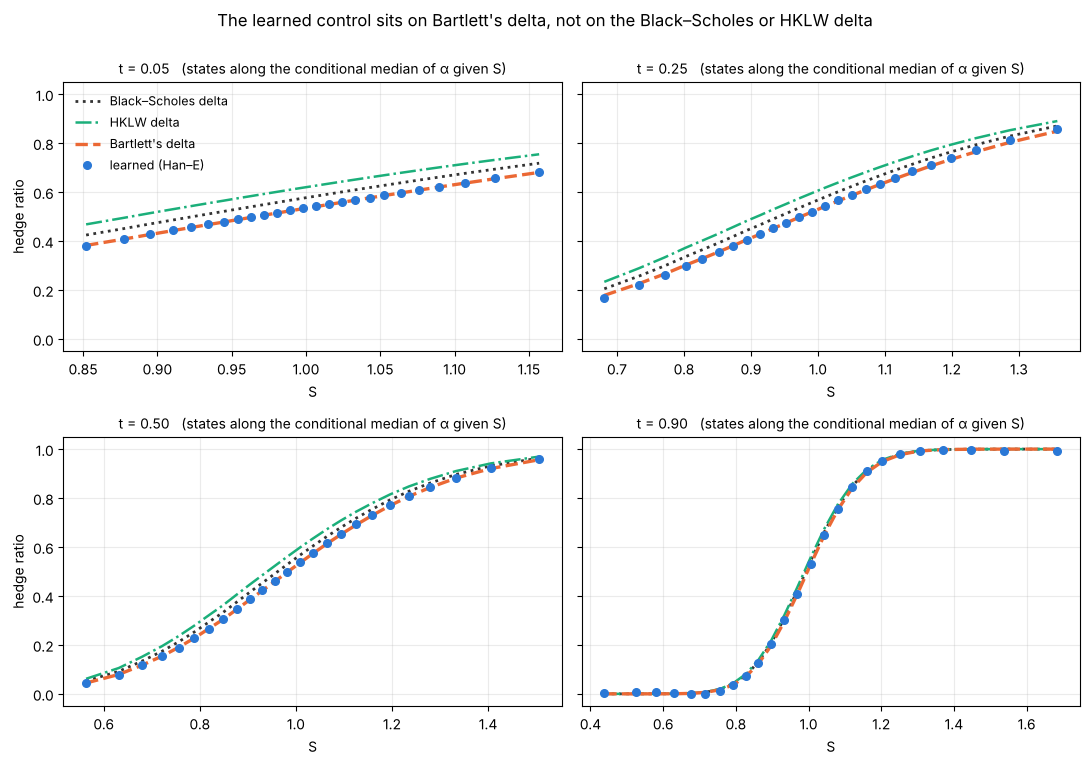

In [8]:
def ridge(k, n_bins=25, lo=0.025, hi=0.975):
    '''Empirical conditional median of alpha_k given S_k: equal-count bins of S_k inside its central 95% (the states the
       policy was actually trained on; with rho = -0.9 a slice at fixed alpha would leave the support of the path law).'''
    s, a = S[:, k], A[:, k]
    order = s.argsort(); s, a = s[order], a[order]
    n = s.numel(); s, a = s[int(lo*n):int(hi*n)], a[int(lo*n):int(hi*n)]
    return torch.stack([x.median() for x in s.chunk(n_bins)]), torch.stack([x.median() for x in a.chunk(n_bins)])

fig, axes = plt.subplots(2, 2, figsize=(11, 7.6), sharey=True)
for ax, k in zip(axes.ravel(), (5, 25, 50, 90)):
    Sr, Ar = ridge(k)
    th = hedge_ratios(Sr, Ar, TAU[k])
    with torch.no_grad(): a_learned = policy.hedge(k, Sr.float(), Ar.float()).double()
    ax.plot(Sr.cpu(), th['bs'].cpu(),       color=COL['bs'],       ls=':',  lw=2.0, label=LABEL['bs'])
    ax.plot(Sr.cpu(), th['hklw'].cpu(),     color=COL['hklw'],     ls='-.', lw=1.8, label=LABEL['hklw'])
    ax.plot(Sr.cpu(), th['bartlett'].cpu(), color=COL['bartlett'], ls='--', lw=2.4, label=LABEL['bartlett'])
    ax.plot(Sr.cpu(), a_learned.cpu(), 'o', color=COL['learned'], ms=5.5, label=LABEL['learned'])
    ax.set_title(f't = {k*dt:.2f}   (states along the conditional median of α given S)', fontsize=10)
    ax.set_xlabel('S'); ax.grid(alpha=0.25)
axes[0, 0].set_ylabel('hedge ratio'); axes[1, 0].set_ylabel('hedge ratio'); axes[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle('The learned control sits on Bartlett\'s delta, not on the Black–Scholes or HKLW delta', y=1.0)
plt.tight_layout(); plt.show()

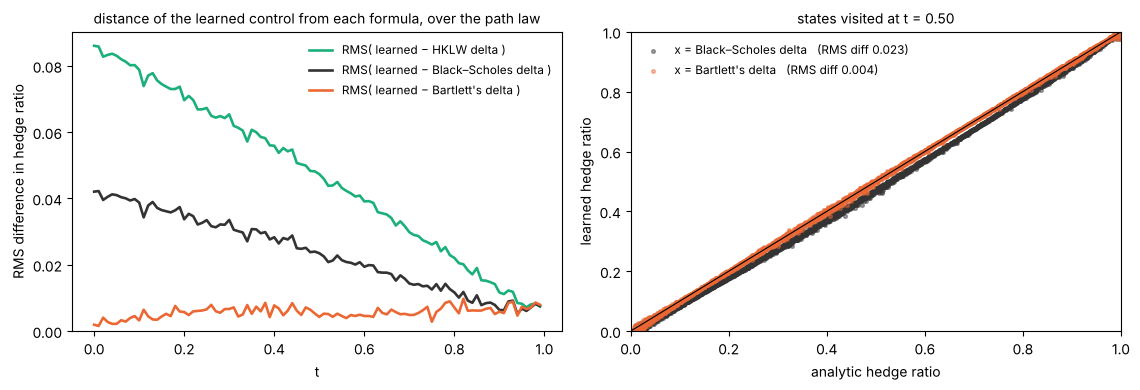

In [9]:
# state-by-state distance between the learned control and each formula, along the test paths
dist = {s: ((theta['learned'] - theta[s])**2).mean(0).sqrt().cpu().numpy() for s in ('bs', 'hklw', 'bartlett')}
t_grid = dt*np.arange(N_STEPS)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
for s in ('hklw', 'bs', 'bartlett'):
    ax[0].plot(t_grid, dist[s], color=COL[s], lw=1.9, label=f'RMS( learned − {LABEL[s]} )')
ax[0].set_xlabel('t'); ax[0].set_ylabel('RMS difference in hedge ratio'); ax[0].set_ylim(bottom=0)
ax[0].legend(frameon=False, fontsize=8.5); ax[0].set_title('distance of the learned control from each formula, over the path law', fontsize=10)

k = N_STEPS//2; idx = torch.randperm(N_TEST, device=device)[:3000]
for s in ('bs', 'bartlett'):
    ax[1].scatter(theta[s][idx, k].cpu(), theta['learned'][idx, k].cpu(), s=7, alpha=0.45, color=COL[s],
                  label=f'x = {LABEL[s]}   (RMS diff {dist[s][k]:.3f})')
ax[1].plot([0, 1], [0, 1], 'k-', lw=0.8); ax[1].set_xlim(0, 1); ax[1].set_ylim(0, 1)
ax[1].set_xlabel('analytic hedge ratio'); ax[1].set_ylabel('learned hedge ratio'); ax[1].legend(frameon=False, fontsize=8.5)
ax[1].set_title(f'states visited at t = {k*dt:.2f}', fontsize=10)
plt.tight_layout(); plt.show()

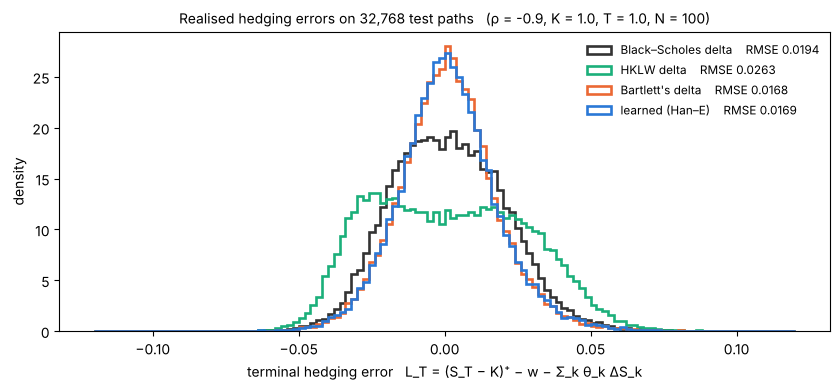

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4))
bins = np.linspace(-0.12, 0.12, 121)
for s in ('bs', 'hklw', 'bartlett', 'learned'):
    ax.hist(L[s].cpu().numpy(), bins=bins, density=True, histtype='step', lw=1.9, color=COL[s], label=f'{LABEL[s]}    RMSE {rmse[s]:.4f}')
ax.set_xlabel('terminal hedging error   L_T = (S_T − K)⁺ − w − Σ_k θ_k ΔS_k'); ax.set_ylabel('density'); ax.legend(frameon=False, fontsize=8.5)
ax.set_title(f'Realised hedging errors on {N_TEST:,} test paths   (ρ = {RHO}, K = {K}, T = {T}, N = {N_STEPS})', fontsize=10)
plt.tight_layout(); plt.show()

## 4. Reading the results

* **The learned control is Bartlett's delta.** Along the states the paths actually visit, the RMS distance between the
  Han–E policy and Bartlett's delta is an order of magnitude smaller than its distance to the Black–Scholes delta
  (panel 1 of the distance plot; the slices; the scatter). At $t=0$ the learned $a_0$ reproduces Bartlett's number, well
  away from $\Phi(\hat d_+)$. The network never saw $\hat\Sigma$, $F_1$, $F_2$ or $\rho$ explicitly — it recovered the
  $\rho F_1$ term (the $E[d\alpha\mid dS]$ correction) from the path law and the quadratic objective alone. Close to
  maturity the three formulas merge (their difference is $\propto\sqrt{T-t}$) and the learned control stays within a few
  hundredths of all of them; what remains there is the gap between the discrete-grid optimum — a one-step regression
  coefficient over a move of size $\alpha\sqrt{\Delta t}$ — and any continuous-time delta, plus Monte-Carlo noise.
* **Hedging errors rank as the paper predicts** for $\rho=-0.9$: learned $\approx$ Bartlett $<$ Black–Scholes $<$ HKLW
  (KR22 Thm 3.2 and eq. (26)); the learned RMSE is at or slightly below Bartlett's, because the network optimises the
  discrete-grid problem under the *true* price process rather than under the approximation $\hat\Sigma$.
* **The learned initial capital** converges to the Monte-Carlo price $E[(S_T-K)^+]$, as it must for a martingale $S$;
  the gap to the $\hat\Sigma$ price is the $O(T)$ term that $\hat\Sigma$ drops.

**Caveats / knobs.** The benchmark is "within approximation" ($\hat\Sigma\approx\Sigma$); the discrete grid adds a
rebalancing error common to all strategies; the policy is trained for one $(K,T)$ and is only reliable where paths go.
Things worth trying next: $\rho=0$ (learned should collapse onto HKLW = Bartlett, still $\ne$ Black–Scholes),
$\rho=-0.6$ (the advantage shrinks to a few percent, KR22 Fig. 1), other strikes, a finer grid, and $\beta<1$ — which needs
Hagan's general formula and Bartlett's $\rho\nu/F^\beta$ term, i.e. the stability-in-$\beta$ question of Hagan–Lesniewski (2017).